Setup and Storing Data

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

data_frame = pd.read_csv('STATIC_INFLATIONCALC.csv', skiprows=8) #Read the CSV file and skip the first 8 rows and put it into a dataframe
data_frame = data_frame.rename(columns={'date': 'Date', 'STATIC_INFLATIONCALC': 'CPI'}) #rename the columns for easier access


Input functions

In [ ]:
def basket_price(): #input for the basket price and validation 
    while True:
        try:
            price = float(input("Enter the price of the basket of goods ($): "))
            if price <= 0: #Cannot be negative or zero
                print("Basket price must be a positive number.")
                continue
        except ValueError: #Must be a number
            print("Please enter a valid number for the basket price.")
        else:
            return price

def date1(): #input for the first date and validation
    while True:
        try:
            CPI1_Year = int(input("Enter the first year (YYYY):"))
            CPI1_Month = int(input("Enter the first month (MM):"))
            if CPI1_Year < 1914 or CPI1_Year > 2026: #Max and Min Year
                print("Please enter a year between 1914 and 2026.")
                continue
            if CPI1_Month < 1 or CPI1_Month > 12: #Must be a valid month
                print("Please enter a valid month between 01 and 12.")
                continue
            if (CPI1_Year,CPI1_Month) > (2026, 9): #Max Date
                print("Please enter a date that is before September 2026.")
                continue
        except ValueError: #Must be a number
            print("Please enter valid numbers for the year and month.")
        else:
            return CPI1_Year, CPI1_Month

def date2(CPI1_Year, CPI1_Month):
    while True:
        try:
            CPI2_Year = int(input("Enter the second year (YYYY):"))
            CPI2_Month = int(input("Enter the second month (MM):"))
            if CPI2_Year < 1914 or CPI2_Year > 2026: #Max and Min Year
                print("Please enter a year between 1914 and 2026.")
                continue
            if CPI2_Month < 1 or CPI2_Month > 12: #Must be a valid month
                print("Please enter a valid month between 01 and 12.")
                continue
            if (CPI2_Year,CPI2_Month) > (2026, 9): #Max Date
                print("Please enter a date that is no later than September 2026.")
                continue
        except ValueError: #Must be a number
            print("Please enter valid numbers for the year and month.")
        else:
            return CPI2_Year, CPI2_Month

price = basket_price()
CPI_date1 = date1()
CPI_date2 = date2(*CPI_date1)

Calculations 

In [3]:
data_frame["Year"] = data_frame["Date"].str[0:4].astype(int) #Since the data is in format YYYY-MM, str[0:4] will get the year to compare with the input year
data_frame["Month"] = data_frame["Date"].str[5:7].astype(int) #Since the data is in format YYYY-MM, str[5:7] will get the month to compare with the input month


def get_cpi1(year, month): #Find the CPI value for the first date
    row = data_frame[(data_frame["Year"] == int(year)) & (data_frame["Month"] == int(month))]
    return row["CPI"].iloc[0]
def get_cpi2(year, month): #Find the CPI value for the second date
    row = data_frame[(data_frame["Year"] == int(year)) & (data_frame["Month"] == int(month))]
    return row["CPI"].iloc[0]

try:
    get_cpi1_value = get_cpi1(*CPI_date1)
    get_cpi2_value = get_cpi2(*CPI_date2)
except IndexError: #If the date is not in the dataset, print an error message
    print("Error: One or both date values are not in the dataset.")

def basket_cost2(cpi1, cpi2): #Calculate the cost of the basket of goods in the second date
    return print(f"Basket Cost in {CPI_date2}: ${price * (cpi2 / cpi1):.2f}")
def percentage_change(cpi1, cpi2): #Calculate the percentage change in CPI between the two dates
    return print(f"Percentage Change: {((cpi2 - cpi1) / cpi1) * 100:.2f}%")
def number_of_years(year1, year2): #Calculate the number of years between the two dates
    return print(f"Number of Years: {year2 - year1}")
def average_annual_inflation_rate(cpi1, cpi2, year1, year2): #Calculate the average annual inflation rate between the two dates
    return print(f"Average Annual Inflation Rate: {((cpi2 / cpi1) ** (1 / (year2 - year1)) - 1) * 100:.2f}%")

print(f"CPI Rate in {CPI_date1}: {get_cpi1_value}") #Print the CPI rate for the first date
print(f"CPI Rate in {CPI_date2}: {get_cpi2_value}") #Print the CPI rate for the second date
basket_cost2_value = basket_cost2(get_cpi1_value, get_cpi2_value)
percentage_change_value = percentage_change(get_cpi1_value, get_cpi2_value)
number_of_years_passed = number_of_years(CPI_date1[0], CPI_date2[0])
average_annual_inflation_rate_value = average_annual_inflation_rate(get_cpi1_value, get_cpi2_value, CPI_date1[0], CPI_date2[0])


CPI Rate in (2020, 9): 136.9
CPI Rate in (1999, 9): 93.6
Basket Cost in (1999, 9): $68.37
Percentage Change: -31.63%
Number of Years: -21
Average Annual Inflation Rate: 1.83%


Graph

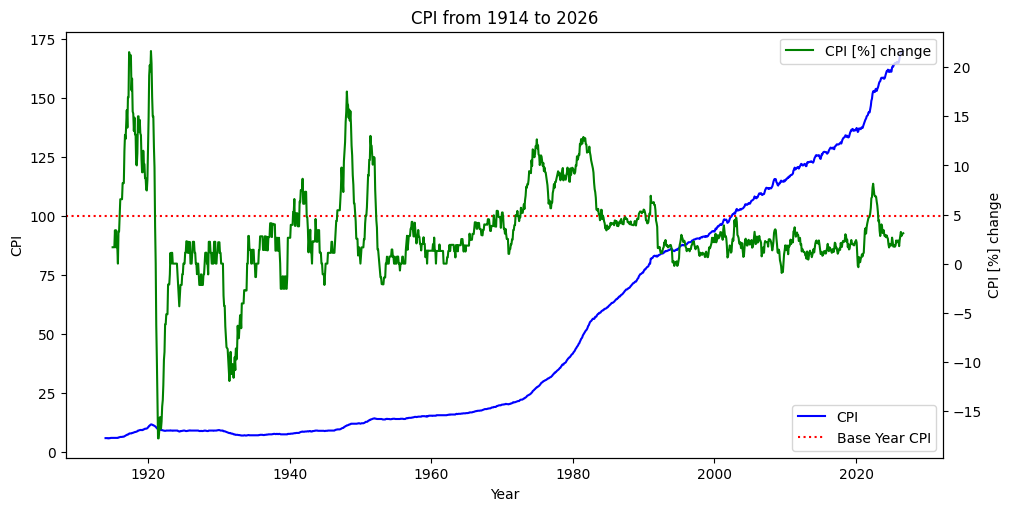

In [4]:
data_frame['Date'] = pd.to_datetime(data_frame['Date']) #Convert the 'Date' column to datetime format for plotting
fig,ax = plt.subplots(figsize=(10, 5), layout='constrained') #Create a figure and axis for the plot with a specified size and constrained layout
ax.plot(data_frame['Date'], data_frame['CPI'], label='CPI', color='blue') #Plot the CPI data on the primary y-axis with a blue line and label it as 'CPI' 
ax.set_title('CPI from 1914 to 2026') #Setting title and labels
ax.set_xlabel('Year')
ax.set_ylabel('CPI')
ax1 = ax.twinx() #Create a secondary y-axis that shares the same x-axis as the primary y-axis
ax1.set_ylabel('CPI [%] change') #Set the label for the secondary y-axis
line1 = ax1.plot(data_frame['Date'], 100 * (data_frame['CPI'] / data_frame['CPI'].shift(12) - 1), color='green', label='CPI [%] change') #Plot the CPI percentage change on the secondary y-axis
line2 = ax.axhline(y=100, color='red', linestyle=':', label='Base Year CPI') #Base Year CPI line at 100
ax.legend(loc='lower right') #Create a legend for the two axis and save the figure
ax1.legend(loc='upper right') 
fig.savefig('CPI_graph.png')